# Практическая работа №2: Исследование подгрупп сетей. Сети аффилированности.

Выполнила студентка гр. 4385 Касимова Варвара Андреевна. Вариант №4.

## Цель работы

Овладеть навыками работы с математическими пакетами для исследования подгрупп в социальных сетях, а также моделирования, отображения и анализа сетей аффилированности.

## Основные теоретические положения

Точка сочленения - актор, при удалении которого граф распадаетя на компоненты связности.

Мост - ребро, при удалении которого граф распадаетя на компоненты связности.

Централизация - мера ыделенности центрального актора.

$$
C_A = \frac{\sum_{i=1}^g{(C_A(n^*) - C_A(n_i))}}{max\sum_{i=1}^g{(C_A(n^*) - C_A(n_i))}}
$$

где $C_A(n_i)$ - мера центральности узла,
$n^*$ - узел с наибольшей центральностью.

k-ядро - подграф, каждый узел которого смежен как минимум с k другими узлами.

Модулярность - мера плотности связей внутри сообществ по сравнению со случайым графом.

$$
Q = \frac{1}{2l} \sum_{i, j}{(a_{ij} - \frac{deg(n_i) \cdot deg(n_j)}{2l})} \mathbb{I}_{\text{{i, j в одной группе}}}
$$

Степень участия акотра - доля собыий, в которых участвует актор, по отношению к общему числу событий.

Размер события - количество акторов, участвующих в событии.

Отношение шансов
$$
ϴ_{kl} = \frac{x^M_{kl} / x^M_{k\overline{l}}}{x^M_{\overline{k}l} / x^M_{\overline{k}\overline{l}}}
$$

## Постановка задачи

С помощью математических пакетов и соответствующих библиотек провести анализ заданных социальных сетей на предмет подгрупп. Провести исследование сети аффилированности CEO. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы

1. Из файла florentine_marital.csv извлечь социоматрицу с помощью соответствующих функций. Отобразить сеть с помощью одного из алгоритмов укладки.

In [1]:
# установим и подкючим библиотеку для работы с графами
install.packages("igraph")
library(igraph)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


Attaching package: ‘igraph’


The following objects are masked from ‘package:stats’:

    decompose, spectrum


The following object is masked from ‘package:base’:

    union




Warning message:
“The `adjmatrix` argument of `graph_from_adjacency_matrix()` must be symmetric
with mode = "undirected" as of igraph 1.6.0.
ℹ Use mode = "max" to achieve the original behavior.”


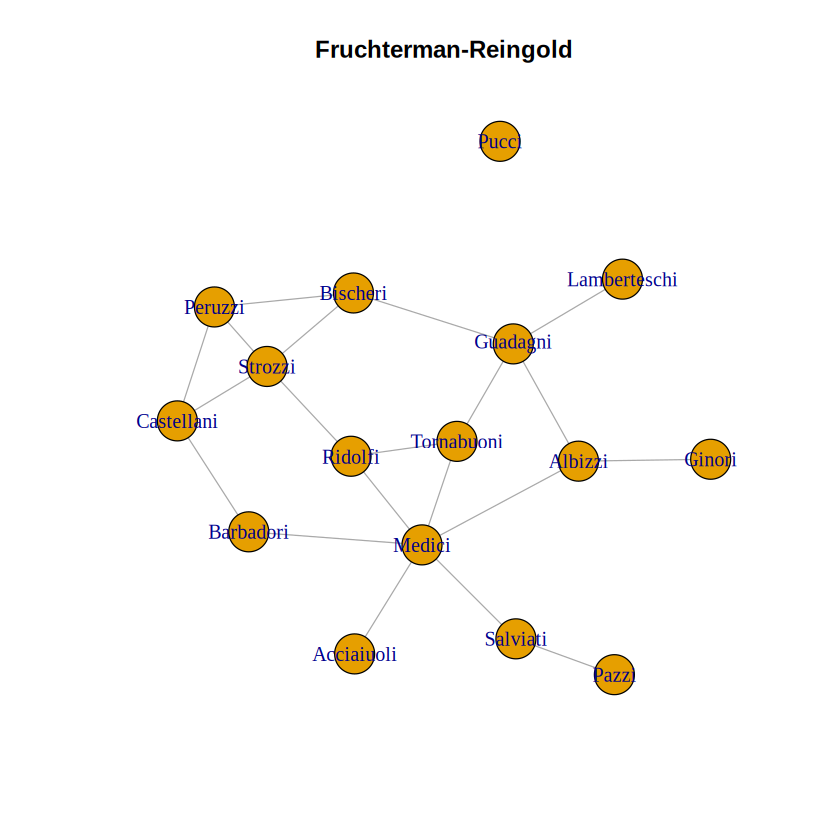

In [2]:
# использую код из предыдущей практической работы, чтобы извлечь матрицу и изобразить граф,
# использую алгоритм укладки Фрюхтермана-Рендгольда, как наиболее наглядный по сравнению с Камада-Каваи
data <- read.csv("florentine_marital.csv", sep = ",", comment.char = "#")
mat <- as.matrix(data)
graf <- graph_from_adjacency_matrix(mat, mode = "undirected")
plot(graf, layout = layout_with_fr, main = "Fruchterman-Reingold")


2. Выявить точки сочленения и мосты сети. Подтвердить свои догадки с помощью соответствующих функций. Построить графики сети, на котором выделены точки сочленения и мосты.

По изображению графа сети нетрудно заметить, что если удалить одну из семей: Medici, Salviati, Albizzi или Guadagni, то граф распадется на большее количество компонент связности.  

Также число компонент связности увеличится, если удалить одну из связей между семьями: Acciaiuoli и Medici, Medici и Salviati, Salviati и Pazzi,  Albizzi и Ginori, Guadagni и Lamberteschi.

In [4]:
articulation_points(graf)
bridges(graf)

+ 4/16 vertices, named, from 4b9e33d:
[1] Albizzi  Guadagni Medici   Salviati

+ 5/20 edges from 4b9e33d (vertex names):
[1] Albizzi   --Ginori       Guadagni  --Lamberteschi Pazzi     --Salviati    
[4] Medici    --Salviati     Acciaiuoli--Medici      

3. Вычислить значение централизации для каждой меры. Сделать выводы.

In [44]:
# централизация по степени
cd <- centr_degree(graf, loops = FALSE)
cd$centralization
# централизация по близости
cc <- centr_clo(graf, mode = "all")
cc$centralization
# централизация по посредничеству
cb <- centr_betw(graf, directed = FALSE)
cb$centralization
# централизация по собственным векторам
ce <- centr_eigen(graf, directed = FALSE)
ce$centralization

[1] 0.2666667

[1] NaN

[1] 0.3834921

[1] 0.5614437

4. Исследовать данную сеть на предмет подгрупп с помощью k-ядер. Указать какие подгруппы получились. Сделать выводы.

В 0-ядро входят все вершины.

В 1-ядро все, кроме Pucci, так как оони не имеют связи ни с кем из других семей.

Для построения 2-ядра удалим из графа все вершины, имеющие только одну связь (изначально или после удаления некоторых акторов, имеющих 1 связь). Таким образом, в 2-ядро не войдут Ginori, Lamberteschi, Pazzi, Salviati, Acciaiuoli и Pucci.

Для построения 3-ядра будем удалять из графа тех, кто в какой-то момент имеет менее 3 соседей, то есть удалим Albizzi, Barbadori (имеют 2 соседей по итогам пострения 2-ядра), Castellani, Guadagni, Medici (потеряли соседей при построении 3-ядра), Bischeri, Peruzzi, Ridolfi, Strozzi, Tornabuoni (тоже потеряли третьего соседа). Таким образом, не осталось никого.

Вывод программы показывает максимальный номер ядра, в которое входит каждая семья.

In [11]:
coreness(graf, mode = "all")

Acciaiuoli      Albizzi    Barbadori     Bischeri   Castellani       Ginori 
           1            2            2            2            2            1 
    Guadagni Lamberteschi       Medici        Pazzi      Peruzzi        Pucci 
           2            1            2            1            2            0 
     Ridolfi     Salviati      Strozzi   Tornabuoni 
           2            1            2            2

5. С помощью библиотеки igraph исследовать алгоритмы обнаружения сообществ:

  * Edge-betweenness;
  * Leading eigenvector;
  * Fast-greedy.

    Кратко объяснить суть каждого алгоритма. Вывести значение модулярности и отобразить полученные сообщества. Сделать выводы.

Алгоритм Edge-betweenness

1. Для каждого узла считается его центраьность по посредничеству (сколько кратчайших путей проходит через него)
2. Ребро с самой большой центральностью яляется мостом и исключается из графа.
3. Пункты 1 и 2 повторяются, пока есть ребра.
4. Выбирается разбиение с максимально модулярностью.

IGRAPH clustering edge betweenness, groups: 5, mod: 0.4
+ groups:
  $`1`
  [1] "Acciaiuoli" "Medici"     "Ridolfi"    "Tornabuoni"
  
  $`2`
  [1] "Albizzi"      "Ginori"       "Guadagni"     "Lamberteschi"
  
  $`3`
  [1] "Barbadori"  "Bischeri"   "Castellani" "Peruzzi"    "Strozzi"   
  
  $`4`
  + ... omitted several groups/vertices

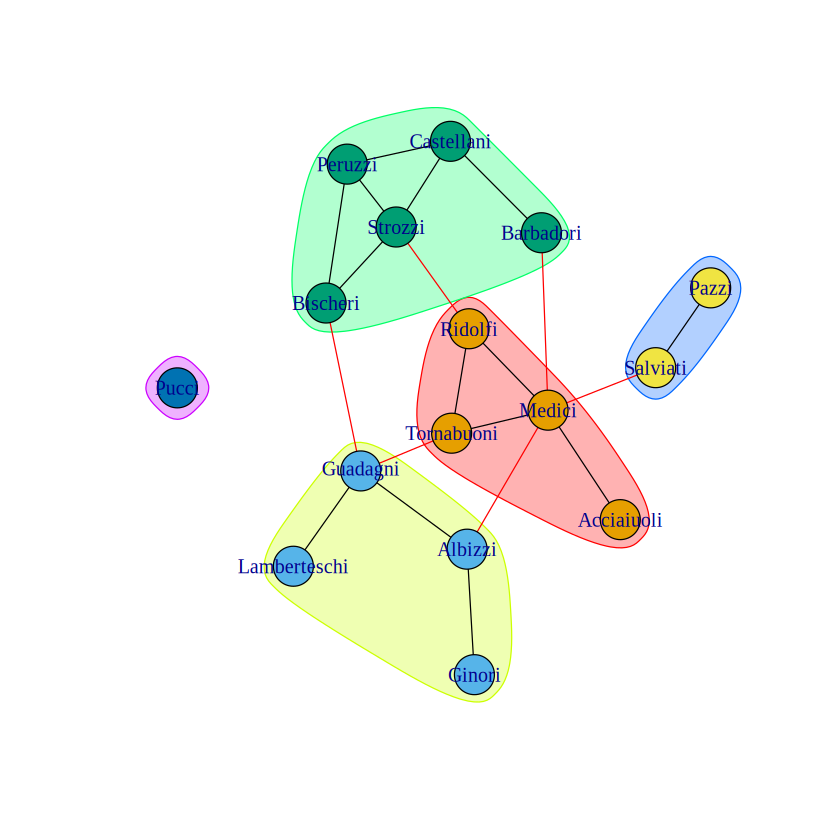

In [31]:
# алгоритм Edge-betweenness;
c1 <- cluster_edge_betweenness(graf)
c1
plot(c1, graf)

Алгоритм Leading eigenvector

1. Строится матрица модулярности $B$:
$$
(B_{ij})_{n \times n} = (A_{ij} - \frac{deg(n_i) \cdot deg(n_j)}{2l})_{n \times n}
$$
2. Находится наиболшее собственное чило и его собственный вектор.
3. Если $i$-тая компонента положительна, узел $n_i$ относится к 1 кластеру, иначе - ко 2.
4. Пункты 1-3 повторяются для каждого кластера, пока их собственное число положительно.

IGRAPH clustering leading eigenvector, groups: 4, mod: 0.36
+ groups:
  $`1`
  [1] "Acciaiuoli" "Barbadori"  "Medici"     "Pazzi"      "Ridolfi"   
  [6] "Salviati"  
  
  $`2`
  [1] "Pucci"
  
  $`3`
  [1] "Bischeri"   "Castellani" "Peruzzi"    "Strozzi"   
  
  + ... omitted several groups/vertices

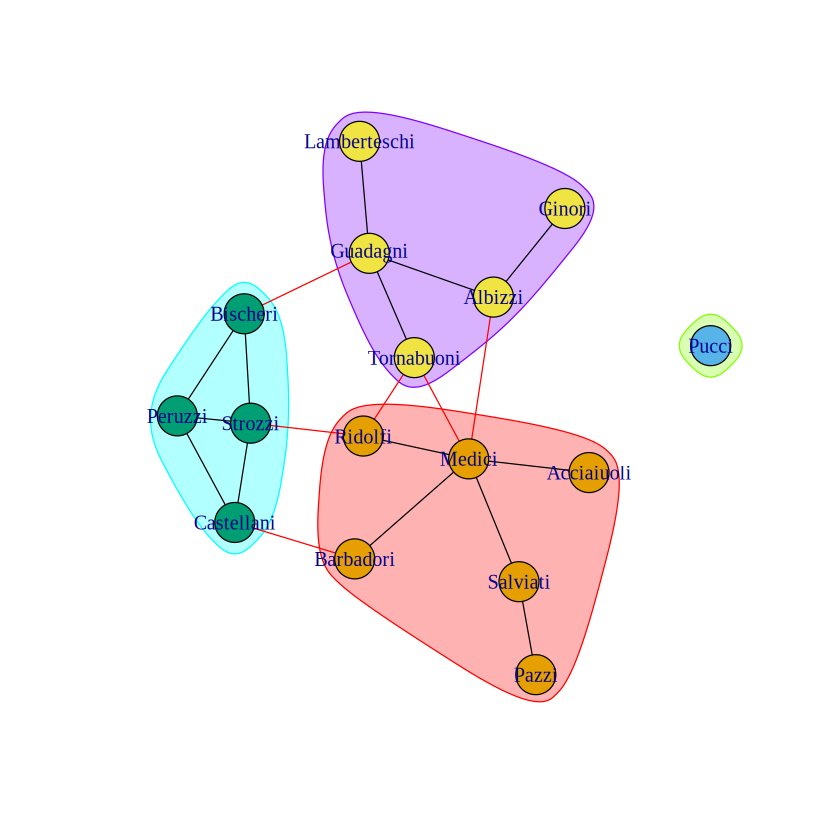

In [32]:
# алгоритм Leading eigenvector
c2 <- cluster_leading_eigen(graf)
c2
plot(c2, graf)

Алгоритм Fast-greedy

1. Поместить каждую вершину в собственный кластер.
2. Найти пару кластеров, объединение которых максимизирует $\Delta Q$ (матрица, которая в каждой ячейке хранит приращение модулярности, если слить вместе соотетствующие кластеры).
3. Объединить их и обновить матрицу приростов модулярности.
4. Повторять пункты 2 и 3, пока все вершины не сольются в один кластер.
5. Зафиксировать состояние с наибольшим значением $Q$.

IGRAPH clustering fast greedy, groups: 4, mod: 0.4
+ groups:
  $`1`
  [1] "Acciaiuoli" "Medici"     "Pazzi"      "Ridolfi"    "Salviati"  
  [6] "Tornabuoni"
  
  $`2`
  [1] "Albizzi"      "Ginori"       "Guadagni"     "Lamberteschi"
  
  $`3`
  [1] "Barbadori"  "Bischeri"   "Castellani" "Peruzzi"    "Strozzi"   
  
  + ... omitted several groups/vertices

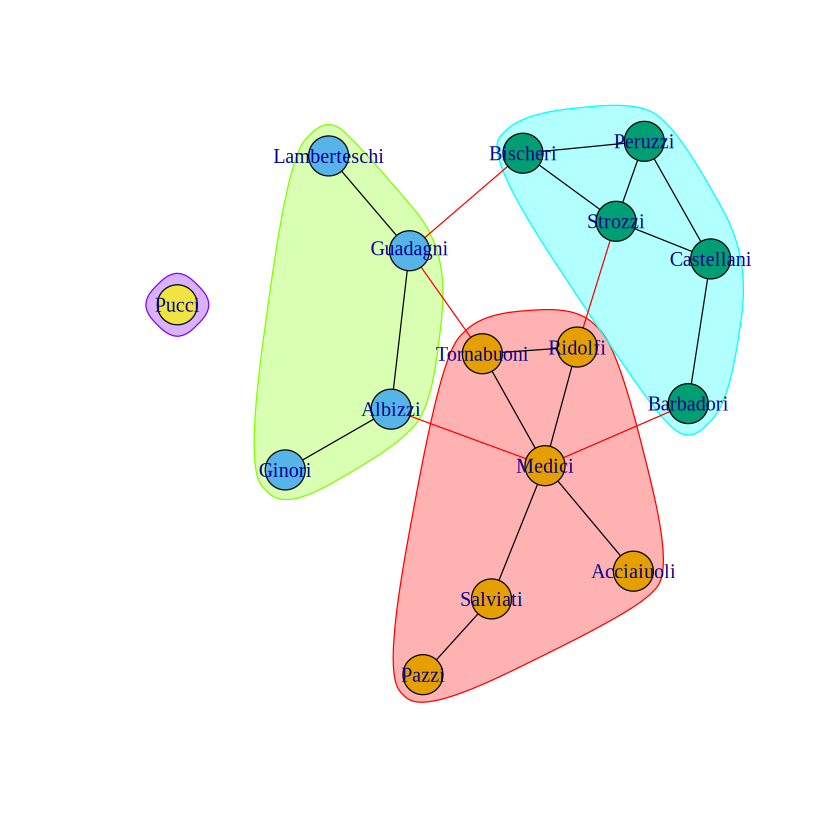

In [33]:
# алгоритм Fast-greedy
c3 <- cluster_fast_greedy(graf)
c3
plot(c3, graf)

6. Из файла ceo.csv извлечь матрицу инцидентности с помощью соответствующих функций. Отобразить полученную матрицу.

In [55]:
data2 <- read.csv("ceo.csv", sep = ",", comment.char = "#", header = FALSE)
mat2 <- as.matrix(data2)
colnames(mat2) <- NULL
mat2

0,0,1,1,0,0,0,0,1,0,0,0,0,0,0
0,0,1,0,1,0,1,0,0,0,0,0,0,0,0
0,0,1,0,0,0,0,0,0,0,0,1,0,0,0
0,1,1,0,0,0,0,0,0,0,0,0,0,0,1
0,0,1,0,0,0,0,0,0,0,0,0,1,1,0
0,1,1,0,0,0,0,0,0,0,0,0,0,1,0
0,0,1,1,0,0,0,0,0,1,1,0,0,0,0
0,0,0,1,0,0,1,0,0,1,0,0,0,0,0
1,0,0,1,0,0,0,1,0,1,0,0,0,0,0
0,0,1,0,0,0,0,0,1,0,0,0,0,0,0
0,1,1,0,0,0,0,0,1,0,0,0,0,0,0


7. Отобразить сеть в виде биграфа.

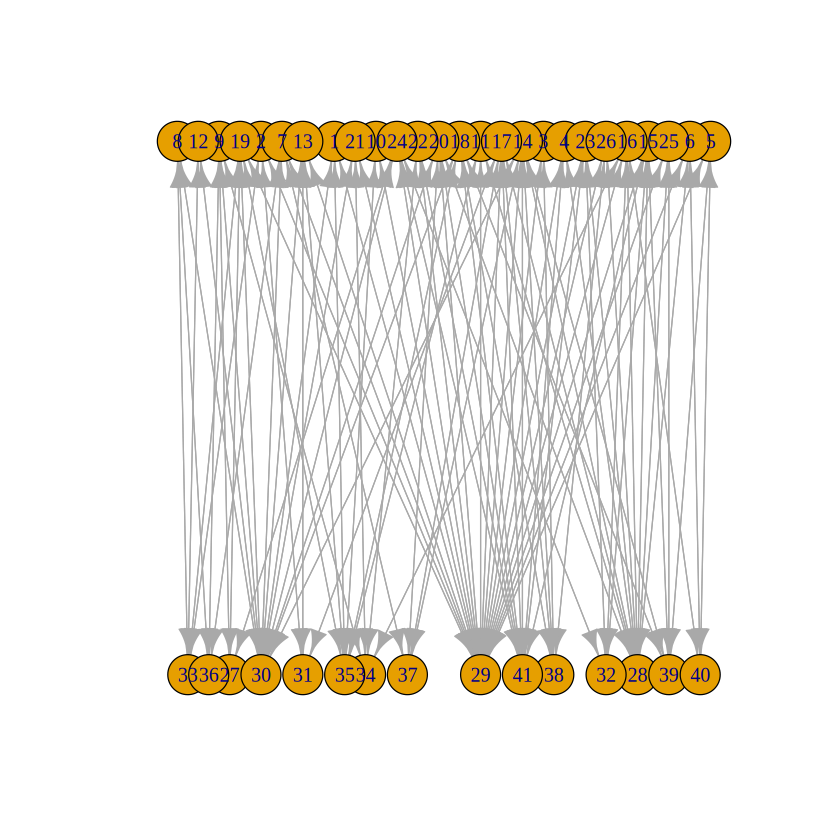

In [54]:
graf2 <- graph_from_biadjacency_matrix(mat2, directed = TRUE, mode = "all")
plot(graf2, layout = layout_as_bipartite)

8. Дополнительное необязательное задание: отобразить сеть в виде гиперграфа и двойственного гиперграфа.

9. Представить сеть аффилированности в виде двух одномодальных сетей: сеть совместного участия акторов и сеть перекрытия событий. Представить полученные сети в виде матриц и взвешенных графов. Сделать выводы.

3,1,1,1,1,1,2,1,1,2,⋯,1,2,3,2,2,1,1,2,1,1
1,3,1,1,1,1,1,1,0,1,⋯,2,0,2,1,1,1,1,1,1,1
1,1,2,1,1,1,1,0,0,1,⋯,2,1,1,1,1,1,1,1,1,2
1,1,1,3,1,2,1,0,0,1,⋯,3,1,1,3,1,2,3,2,2,2
1,1,1,1,3,2,1,0,0,1,⋯,1,1,1,1,1,1,1,1,2,1
1,1,1,2,2,3,1,0,0,1,⋯,2,0,1,2,1,1,2,1,2,2
2,1,1,1,1,1,4,2,2,1,⋯,2,1,2,3,2,1,1,2,1,1
1,1,0,0,0,0,2,3,2,0,⋯,0,1,2,1,1,0,0,1,0,0
1,0,0,0,0,0,2,2,4,0,⋯,0,1,2,1,2,1,0,2,0,0
2,1,1,1,1,1,1,0,0,2,⋯,1,1,2,1,1,1,1,1,1,1
2,1,1,2,1,2,1,0,0,2,⋯,2,1,2,2,1,1,2,1,2,2


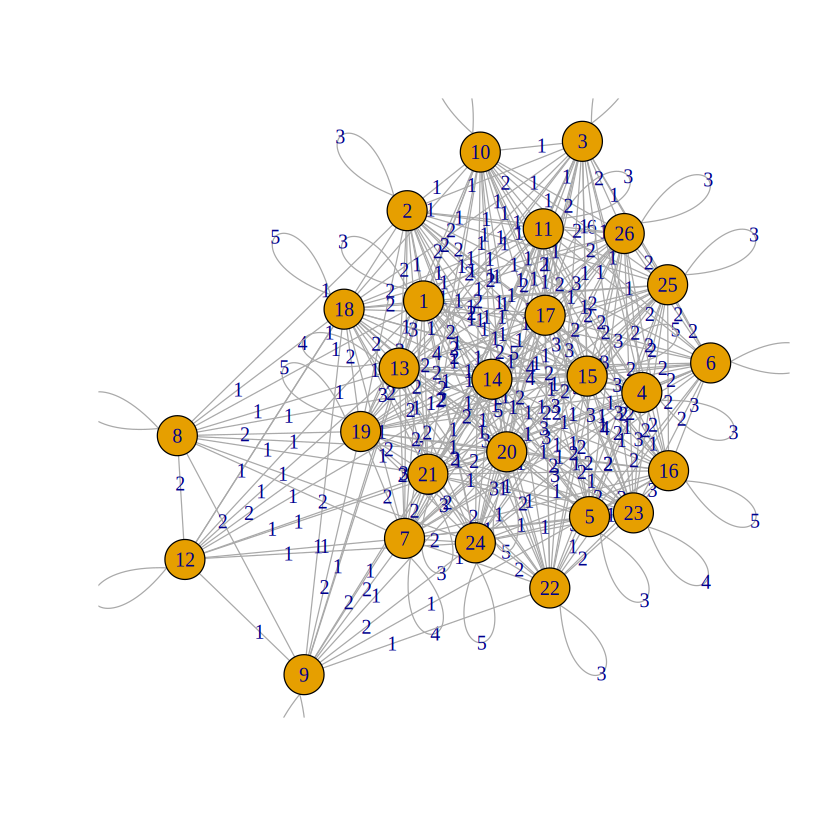

In [93]:
co_membering <- mat2 %*% t(mat2)
co_membering

cm_graf <- graph_from_adjacency_matrix(co_membering, mode = "undirected", weighted = TRUE)
plot(cm_graf, layout = layout_with_fr, edge.label = E(cm_graf)$weight)

3,0,2,3,0,1,1,1,1,1,0,0,0,0,1
0,11,11,2,1,3,0,1,1,0,3,3,3,2,6
2,11,22,8,3,4,2,3,5,1,4,4,4,3,8
3,2,8,12,1,1,3,2,4,3,3,2,2,0,4
0,1,3,1,3,0,1,0,1,0,1,1,0,0,1
1,3,4,1,0,4,0,1,0,0,0,0,1,1,3
1,0,2,3,1,0,4,0,1,1,0,0,0,0,0
1,1,3,2,0,1,0,4,0,1,0,0,0,1,1
1,1,5,4,1,0,1,0,6,0,0,1,1,0,1
1,0,1,3,0,0,1,1,0,3,1,0,0,0,0
0,3,4,3,1,0,0,0,0,1,4,2,1,0,3


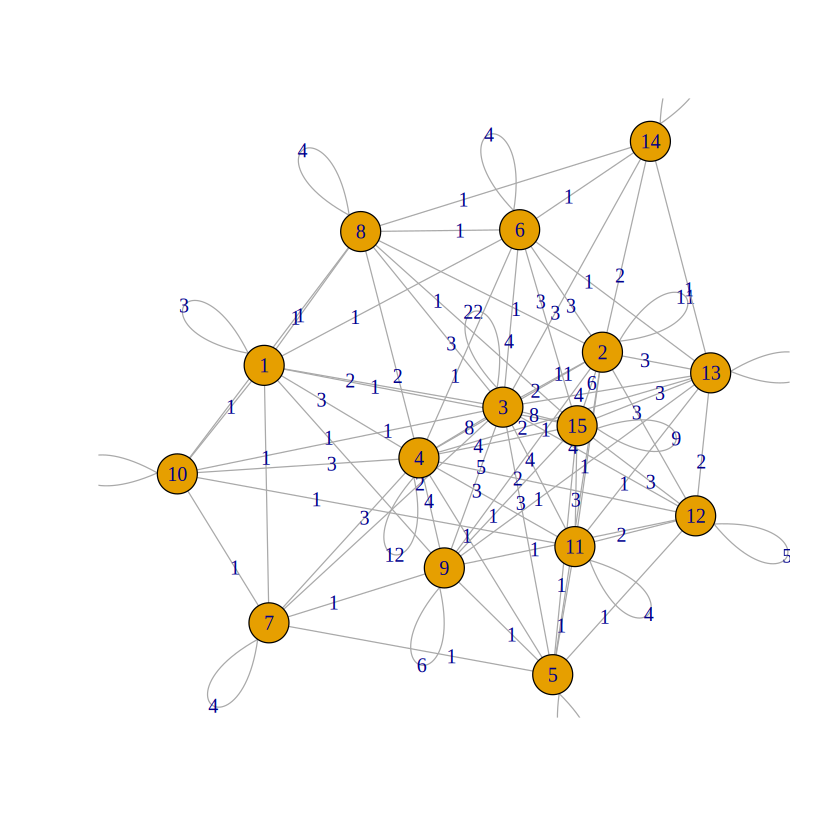

In [94]:
event_overlap <- t(mat2) %*% mat2
event_overlap

eo_graf <- graph_from_adjacency_matrix(event_overlap, mode = "undirected", weighted = TRUE)
plot(eo_graf, layout = layout_with_fr, edge.label = E(eo_graf)$weight)


Построены сеть совместного участия акторов и сеть перекрытия событий.

В матрице совместного участия на диагонали стоит количество событий, в котором участвует актор, в остальных ячейках - количество общих событий для соответствующих акторов.

В матрице перекрытия событий на диагонали стоит количетсво акторов, которые участвуют в событии, в остальных ячейках - количество акторов, которые участвуют в эти двух событиях одновременно.

Взвешенные графы отражают ту же информацию, храня количество общих актором или событий на ребрах.

10. Вычислить степень участия для каждого актора, а также среднее количество событий, с которыми актор аффилирован. Сделать выводы.

Степень участия найдем как диагональные элементы матрицы совместного участия, деленные на общее количество событий. Чтобы найти среднее количество событий, с которыми актор аффилирован, нужно посчитать среднее арифметичекое ненормированной степени участия.

В выводе программы:
1 строка - ненормированная степень участия
2 строка - нормированная степень участия
3 строка - среднее количество событий, с которыми актор аффилирован

In [104]:
degree_part <- co_membering[(0:25) * 27 + 1]
degree_part
cat(" ")
degree_part / 15
cat(" ")
sum(degree_part) / 26

[1] 3 3 2 3 3 3 4 3 4 2 3 2 4 7 5 5 6 5 5 5 3 3 4 5 3 3

[1] 0.2000000 0.2000000 0.1333333 0.2000000 0.2000000 0.2000000 0.2666667
 [8] 0.2000000 0.2666667 0.1333333 0.2000000 0.1333333 0.2666667 0.4666667
[15] 0.3333333 0.3333333 0.4000000 0.3333333 0.3333333 0.3333333 0.2000000
[22] 0.2000000 0.2666667 0.3333333 0.2000000 0.2000000

[1] 3.769231

11. Вычислить размер и средний размер для каждого события. Сделать выводы.

Размер события полчим как диагональный элемент матрицы перекрытия событий, средний размер - среднее арифметическое.

In [105]:
event_size <- event_overlap[(0:14) * 16 + 1]
event_size
cat(" ")
sum(event_size) / 15

[1]  3 11 22 12  3  4  4  4  6  3  4  5  5  3  9

[1] 6.533333

12. Вычислить плотность для отношения совместного участия акторов и отношения перекрытия. Проинтерпретируйте полученные значения.

In [114]:
edge_density(cm_graf, loops = FALSE)

edge_density(eo_graf, loops = FALSE)

[1] 0.9538462

[1] 0.7714286

13. Определить диаметр сети аффилированности.

In [113]:
diameter(cm_graf, directed = FALSE, unconnected = TRUE, weights = E(cm_graf)$weight)
diameter(eo_graf, directed = FALSE, unconnected = TRUE, weights = E(eo_graf)$weight)

[1] 2

[1] 4

14. Для каждых пар событий определить (логарифм) отношение шансов. Сделать выводы.

In [128]:
teta <- matrix(rep(0, 15*15), 15, 15)
for (k in 1:15) {
  for (l in 1:15) {
    Xkl <- event_overlap[k, l]
    Xk_l <- event_overlap[l, l] - event_overlap[k, l]
    Xkl_ <- event_overlap[k, k] - event_overlap[k, l]
    Xk_l_ <- 26 - event_overlap[k, k] - event_overlap[l, l] + event_overlap[k, l]

    teta[k,l] <- Xkl * Xk_l_ / Xkl_ / Xk_l

  }
}
teta

Inf,0.0000000,0.30000000,Inf,0.0000000,3.3333333,3.333333,3.3333333,1.8000000,5.25000000,0.000000,0.0000000,0.0000000,0.000000,0.9375000
0.000000,Inf,Inf,0.1111111,0.6500000,5.2500000,0.000000,0.4000000,0.2000000,0.00000000,5.250000,2.4375000,2.4375000,3.111111,4.8000000
0.300000,Inf,Inf,0.0000000,Inf,Inf,0.100000,0.4736842,0.8823529,0.04761905,Inf,0.6666667,0.6666667,Inf,1.7142857
Inf,0.1111111,0.00000000,Inf,0.5454545,0.3333333,4.333333,1.2000000,3.0000000,Inf,4.333333,0.7333333,0.7333333,0.000000,0.9000000
0.000000,0.6500000,Inf,0.5454545,Inf,0.0000000,3.333333,0.0000000,1.8000000,0.00000000,3.333333,2.3750000,0.0000000,0.000000,0.9375000
3.333333,5.2500000,Inf,0.3333333,0.0000000,Inf,0.000000,2.1111111,0.0000000,0.00000000,0.000000,0.0000000,1.5000000,3.333333,8.0000000
3.333333,0.0000000,0.10000000,4.3333333,3.3333333,0.0000000,Inf,0.0000000,1.1333333,3.33333333,0.000000,0.0000000,0.0000000,0.000000,0.0000000
3.333333,0.4000000,0.47368421,1.2000000,0.0000000,2.1111111,0.000000,Inf,0.0000000,3.33333333,0.000000,0.0000000,0.0000000,3.333333,0.5833333
1.800000,0.2000000,0.88235294,3.0000000,1.8000000,0.0000000,1.133333,0.0000000,Inf,0.00000000,0.000000,0.8000000,0.8000000,0.000000,0.3000000
5.250000,0.0000000,0.04761905,Inf,0.0000000,0.0000000,3.333333,3.3333333,0.0000000,Inf,3.333333,0.0000000,0.0000000,0.000000,0.0000000
0.000000,5.2500000,Inf,4.3333333,3.3333333,0.0000000,0.000000,0.0000000,0.0000000,3.33333333,Inf,6.3333333,1.5000000,0.000000,8.0000000


## Выводы

Были исследованы направленная сеть и сеть аффелированности, исследоаны подгруппы в этих сетях.